# PART 8. 판매자 유형 분석 (비지도 학습 · K-Means)

> **핵심 질문: Olist에는 어떤 유형의 판매자들이 있을까?**

## 📋 한눈에 보기

**작업 흐름**
```
1. 원본 CSV에서 기준일(2018-05-31)까지의 판매자 프로필 만들기
2. 분포 확인 → 로그 변환 전후 비교
3. 엘보우 + 실루엣으로 k 정하기
4. K-Means (k=4) → 유형 이름 붙이기
5. 유형별 지연·평점 해석
6. PCA로 그려 보기
7. 배포용 저장
```

| 항목 | 내용 |
|---|---|
| 사용 데이터 | 원본 CSV (orders, order_items, reviews, sellers) → 판매자 2,502명 |
| 결과물 | `part8_seller_segment.pkl` (약 3KB) → PART 9, 10에서 사용 |

**🎯 핵심 (꼭 가져갈 것)**
- 치우친 값(주문 수·판매액)은 **로그로 펴야** 군집이 제대로 나뉩니다.
- 엘보우로 후보를 좁히고 **실루엣 점수로 결정**합니다. 이름은 사람이 해석해서 붙입니다.

**💡 인사이트 (이 파트에서 확인한 사실)**
- 로그 변환을 안 하면 대형 판매자 22명이 군집 하나를 차지합니다.
- 4가지 유형: 핵심 우량 876 · 신규 성장 947 · 휴면 461 · 저평점 위험 218명
- 저평점 위험 유형은 평균 배송 약 22일, 출고 지연율 약 33%로 **판매자 출고 단계부터 늦습니다.**

---

## 수업 목표
- 판매자 1명 = 1행인 **판매자 프로필**을 원본 데이터에서 직접 만듭니다.
- 로그 변환·스케일링이 군집 결과를 어떻게 바꾸는지 확인합니다.
- **엘보우**로 군집 수 후보를 좁히고 **실루엣 점수**로 결정합니다.
- 군집 결과에 이름을 붙여 **비즈니스 언어로 해석**합니다.

## 수업 진행 포인트
| 구분 | 설명 |
|---|---|
| 데이터 관점 | 주문 단위 데이터를 판매자 단위로 묶습니다(집계). 행을 버리는 것이 아니라 묶는 것입니다. |
| 코드 관점 | `groupby` 집계, `StandardScaler`, `KMeans`, `silhouette_score`, `PCA` 사용법을 익힙니다. |
| AI 관점 | 정답(라벨) 없이 비슷한 것끼리 묶는 **비지도 학습**입니다. 결과 해석은 사람의 몫입니다. |

## PART 5와의 연결
| EDA 결과 (PART 5) | 이 파트에서 |
|---|---|
| 인사이트 9. 배송이 늦으면 리뷰가 무너진다 | 지연과 낮은 평점이 몰린 판매자 그룹이 있는지 찾습니다. |
| 인사이트 10. 성수기·먼 지역에서 배송이 늦어진다 | 지연이 **판매자 출고 구간**과 **택배 운송 구간** 중 어디서 생기는지 확인합니다. |

---

## 📌 이 파트에서 사용하는 API 흐름 (scikit-learn)

| 단계 | 함수 | 역할 |
|---|---|---|
| ① | `groupby().agg()` | 주문 데이터 → 판매자 프로필 |
| ② | `np.log1p()` + `StandardScaler` | 치우친 값 펴기 + 단위 맞추기 |
| ③ | `KMeans(n_clusters=k).fit()` | k개 군집으로 묶기 |
| ④ | `inertia_`, `silhouette_score()` | 군집 수 정하기 (엘보우, 실루엣) |
| ⑤ | `PCA(n_components=2)` | 2차원 그림으로 확인 |
| ⑥ | `joblib.dump()` | 배포용 저장 |

## 핵심 개념

| 개념 | 설명 |
|---|---|
| 비지도 학습 | 정답 없이 데이터의 구조(비슷한 것끼리)를 찾는 학습 |
| RFM | Recency(최근성) · Frequency(빈도) · Monetary(금액). 고객·판매자 분석의 기본 지표 |
| K-Means | 군집 중심 k개를 두고, 각 점을 가장 가까운 중심에 배정하는 것을 반복하는 방법 |
| 엘보우(Elbow) | k를 늘릴 때 오차 합계(inertia)가 줄어드는 폭이 꺾이는 지점을 찾는 방법 |
| 실루엣 점수 | 같은 군집끼리는 가깝고 다른 군집과는 먼 정도 (-1~1, 클수록 좋음) |
| PCA | 여러 특징을 정보 손실을 최소로 하며 2개 축으로 압축해 그림으로 보는 방법 |

In [1]:
# 셀 1. Google Drive 연결

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# 셀 2. 라이브러리 불러오기

# 그래프 한글 깨짐 방지 (Colab에는 한글 폰트가 없어서 □□□로 표시됨)
!pip install -q koreanize-matplotlib

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib  # import만 하면 한글 폰트가 자동 적용됩니다
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

base_path  = "/content/drive/MyDrive/Colab Notebooks/Data_Analysis/Olist"
data_path  = f"{base_path}/data"     # PART 2에서 저장한 원본 CSV 위치
model_path = f"{base_path}/model"    # 학습한 모델을 저장할 위치
os.makedirs(model_path, exist_ok=True)

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
print("경로 설정 완료!")

경로 설정 완료!


---
## 1. 판매자 프로필 만들기

### 왜 기준일(2018-05-31)까지만 쓸까?
PART 9에서는 이 유형을 이용해 "6~8월에 판매를 멈출 판매자"를 해석합니다.
6월 이후 정보가 섞이면 **정답을 미리 보고 푸는 셈**(데이터 누수)이 되므로, 두 파트 모두 **2018-05-31까지의 정보**로만 판매자를 설명합니다.

| 기준 | 내용 |
|---|---|
| 기간 | 2017-01-01 ~ 2018-05-31 (기준일 = 2018-06-01 0시) |
| 주문 | 취소(canceled) · 구매 불가(unavailable) 제외 |
| 단위 | 판매자 1명 = 1행 |

In [3]:
# 셀 3. 원본 데이터 불러오기

date_cols = ["order_purchase_timestamp", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
orders  = pd.read_csv(f"{data_path}/olist_orders_dataset.csv", parse_dates=date_cols)
items   = pd.read_csv(f"{data_path}/olist_order_items_dataset.csv", parse_dates=["shipping_limit_date"])
reviews = pd.read_csv(f"{data_path}/olist_order_reviews_dataset.csv", parse_dates=["review_creation_date"])
sellers = pd.read_csv(f"{data_path}/olist_sellers_dataset.csv")

print(f"주문 {len(orders):,}건 / 판매 상품 {len(items):,}행 / 리뷰 {len(reviews):,}건 / 판매자 {len(sellers):,}명")

주문 99,441건 / 판매 상품 112,650행 / 리뷰 99,224건 / 판매자 3,095명


In [4]:
# 셀 4. 판매자 프로필 함수 (판매자 1명 = 1행)
# ⚠️ 기준일(cutoff) '이전'에 알 수 있었던 정보만 사용합니다.
#    - 기준일 전에 들어온 주문만
#    - 배송 완료·출고 시각도 기준일 전에 일어난 것만
#    - 리뷰도 기준일 전에 작성된 것만
# PART 8 · PART 9 · PART 10(배포)에서 똑같은 함수를 씁니다.

def make_seller_profile(orders, items, reviews, cutoff, start="2017-01-01"):
    cutoff = pd.Timestamp(cutoff)
    o = orders[
        (orders["order_purchase_timestamp"] >= start)
        & (orders["order_purchase_timestamp"] < cutoff)
        & ~orders["order_status"].isin(["canceled", "unavailable"])   # 유효 주문만
    ]
    line = items.merge(o, on="order_id")

    # 판매자-주문 단위로 정리 (한 주문에 같은 판매자 상품이 여러 개면 1행으로)
    so = line.groupby(["seller_id", "order_id"]).agg(
        purchase=("order_purchase_timestamp", "first"),
        carrier=("order_delivered_carrier_date", "first"),     # 택배사에 넘긴 시각 (출고)
        delivered=("order_delivered_customer_date", "first"),  # 고객이 받은 시각
        estimated=("order_estimated_delivery_date", "first"),  # 안내한 도착 예정일
        limit=("shipping_limit_date", "max"),                  # 판매자 출고 마감 시각
        sales=("price", "sum"),
    ).reset_index()

    # 기준일 이후에 일어난 일은 '아직 모르는 정보' → 빈 값으로
    so["carrier"]   = so["carrier"].where(so["carrier"] < cutoff)
    so["delivered"] = so["delivered"].where(so["delivered"] < cutoff)
    score = reviews[reviews["review_creation_date"] < cutoff].groupby("order_id")["review_score"].mean()
    so["score"] = so["order_id"].map(score)

    # 주문별 지표 만들기 (모르는 값은 빈 값(NaN)으로 두고, 평균 낼 때 자동으로 빠집니다)
    so["delivery_days"]  = (so["delivered"] - so["purchase"]).dt.total_seconds() / 86400   # 주문 → 수령까지 걸린 일수
    so["is_late"]        = np.where(so["delivered"].isna(), np.nan, so["delivered"] > so["estimated"])  # 예정일보다 늦게 도착? (1/0)
    so["is_ship_late"]   = np.where(so["carrier"].isna(), np.nan, so["carrier"] > so["limit"])          # 출고 마감보다 늦게 출고? (1/0)
    so["is_low_review"]  = np.where(so["score"].isna(), np.nan, so["score"] <= 2)                        # 1~2점 리뷰? (1/0)
    so["month"]          = so["purchase"].dt.to_period("M")                                             # 주문한 연-월 (예: 2018-03)

    # 판매자 1명 = 1행으로 묶기

    g = so.groupby("seller_id")
    prof = pd.DataFrame({
        "frequency":         g.size(),                                         # F : 주문 건수
        "monetary":          g["sales"].sum(),                                 # M : 판매액 (R$)
        "recency_days":      (cutoff - g["purchase"].max()).dt.days,           # R : 마지막 판매 후 일수
        "tenure_days":       (cutoff - g["purchase"].min()).dt.days,           # 첫 판매 후 일수
        "active_months":     g["month"].nunique(),                             # 판매가 있었던 달 수
        "avg_delivery_days": g["delivery_days"].mean(),                        # 평균 배송 일수
        "late_rate":         g["is_late"].mean(),                              # 고객 도착 지연 비율
        "ship_late_rate":    g["is_ship_late"].mean(),                         # 판매자 출고 지연 비율
        "avg_review_score":  g["score"].mean(),                                # 평균 리뷰 점수
        "low_review_rate":   g["is_low_review"].mean(),                        # 1~2점 리뷰 비율
    })
    prof["avg_order_value"] = prof["monetary"] / prof["frequency"]             # 주문당 평균 금액
    return prof.reset_index()

In [5]:
# 셀 5. 기준일까지의 판매자 프로필 만들기

CUTOFF = "2018-06-01"      # 이 시각 '이전'까지의 정보만 사용 (= 2018-05-31까지)
prof = make_seller_profile(orders, items, reviews, CUTOFF)
prof = prof.merge(sellers[["seller_id", "seller_state"]], on="seller_id", how="left")

print(f"판매자 수 : {len(prof):,}명")
prof.head()

판매자 수 : 2,502명


,seller_id,frequency,monetary,recency_days,tenure_days,active_months,avg_delivery_days,late_rate,ship_late_rate,avg_review_score,low_review_rate,avg_order_value,seller_state
0,0015a82c2db000af6aaaf3ae2ecb0532,3,"2,685.00",225,247,2,10.79,0.00,0.00,3.67,0.33,895.00,SP
1,001cca7ae9ae17fb1caed9dfb1094831,197,"24,709.13",33,481,15,13.21,0.06,0.06,3.97,0.16,125.43,ES
2,002100f778ceb8431b7a1020ff7ab48f,51,"1,234.50",49,259,8,16.39,0.18,0.08,3.90,0.16,24.21,SP
3,003554e2dce176b5555353e4f3555ac8,1,120.00,167,167,1,4.65,0.00,0.00,5.00,0.00,120.00,GO
4,004c9cd9d87a3c30c522c48c4fc07416,158,"19,712.71",28,489,17,14.81,0.08,0.00,4.15,0.12,124.76,SP


### 📋 판매자 프로필 컬럼

| 컬럼 | 설명 | 구분 |
|---|---|---|
| frequency | 주문 건수 | F (빈도) |
| monetary | 판매액 합계 (R$, 배송비 제외) | M (금액) |
| recency_days | 마지막 판매 후 기준일까지 지난 일수 | R (최근성) |
| tenure_days | 첫 판매 후 기준일까지 지난 일수 | 활동 기간 |
| active_months | 판매가 있었던 달의 수 | 활동 |
| avg_order_value | 주문당 평균 금액 | 금액 |
| avg_delivery_days | 주문부터 고객 수령까지 평균 일수 | 운영 |
| late_rate | 안내한 도착 예정일보다 늦게 도착한 비율 | 운영 |
| ship_late_rate | 판매자가 출고 마감 시각보다 늦게 택배사에 넘긴 비율 | 운영 |
| avg_review_score | 평균 리뷰 점수 | 평판 |
| low_review_rate | 1~2점 리뷰 비율 | 평판 |

       frequency   monetary  recency_days  tenure_days  avg_review_score
count   2,502.00   2,502.00      2,502.00     2,502.00          2,449.00
mean       32.00   4,340.30        111.80       269.30              4.00
std        99.00  13,234.30        137.60       160.90              0.90
min         1.00       3.50          0.00         0.00              1.00
25%         2.00     218.10         12.00       126.00              3.80
50%         6.00     831.30         42.00       263.00              4.10
75%        23.00   3,359.00        181.00       429.00              4.50
max     1,602.00 196,508.80        498.00       511.00              5.00


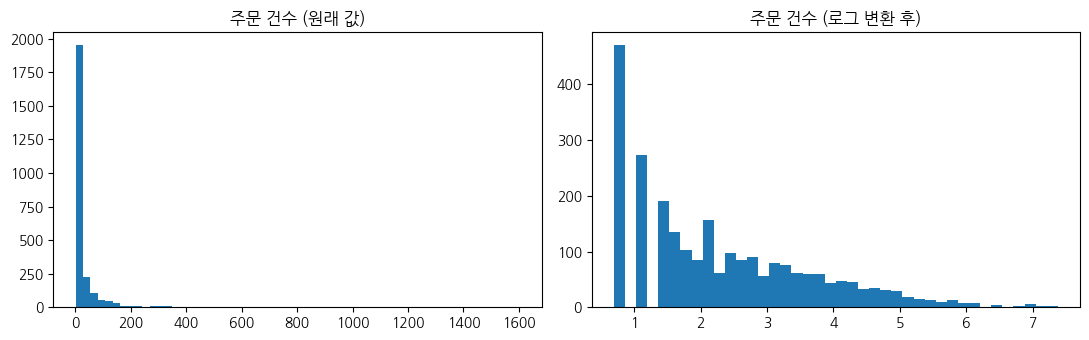

In [6]:
# 셀 6. 분포 확인 : 판매 건수와 판매액은 어떻게 퍼져 있을까?

print(prof[["frequency", "monetary", "recency_days", "tenure_days", "avg_review_score"]].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(prof["frequency"], bins=60); axes[0].set_title("주문 건수 (원래 값)")
axes[1].hist(np.log1p(prof["frequency"]), bins=40); axes[1].set_title("주문 건수 (로그 변환 후)")
plt.tight_layout(); plt.show()

**해석**: 대부분의 판매자는 주문이 몇 건뿐이고, 소수의 판매자만 수백~천 건 넘게 팝니다. 오른쪽으로 길게 늘어진 분포입니다.
로그 변환을 하면 고르게 펴집니다.

---
## 2. 군집 입력 만들기

| 특징 | 의미 | 전처리 |
|---|---|---|
| log_frequency | 얼마나 자주 팔았나 | 로그 변환 |
| log_monetary | 얼마나 많이 팔았나 | 로그 변환 |
| recency_days | 최근에도 파는가 | 그대로 |
| tenure_days | 얼마나 오래 활동했나 | 그대로 |
| avg_review_score | 평판은 어떤가 | 리뷰가 없는 판매자는 중앙값으로 채움 |

> 모든 특징은 마지막에 `StandardScaler`로 단위를 맞춥니다.

In [7]:
# 셀 7. 군집 입력 만들기

# 군집에 쓰는 특징 (PART 8에서 정한 것)
seg_features = ["log_frequency", "log_monetary", "recency_days", "tenure_days", "avg_review_score"]

def make_segment_input(prof, review_fill):
    """판매자 프로필 → 군집 입력 (로그 변환 + 결측 채우기)"""
    return pd.DataFrame({
        "log_frequency":    np.log1p(prof["frequency"]),
        "log_monetary":     np.log1p(prof["monetary"]),
        "recency_days":     prof["recency_days"],
        "tenure_days":      prof["tenure_days"],
        "avg_review_score": prof["avg_review_score"].fillna(review_fill),
    })

review_fill = prof["avg_review_score"].median()     # 리뷰가 없는 판매자에게 채울 값
print(f"리뷰가 없는 판매자 : {prof['avg_review_score'].isna().sum()}명 → 중앙값 {review_fill:.2f}점으로 채움")

X = make_segment_input(prof, review_fill)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X.describe().round(2)

리뷰가 없는 판매자 : 53명 → 중앙값 4.14점으로 채움


,log_frequency,log_monetary,recency_days,tenure_days,avg_review_score
count,"2,502.00","2,502.00","2,502.00","2,502.00","2,502.00"
mean,2.27,6.76,111.83,269.29,3.98
std,1.38,1.84,137.60,160.93,0.94
min,0.69,1.50,0.00,0.00,1.00
25%,1.10,5.39,12.00,126.00,3.75
50%,1.95,6.72,42.00,263.00,4.14
75%,3.18,8.12,181.00,429.00,4.50
max,7.38,12.19,498.00,511.00,5.00


In [8]:
# 셀 8. 로그 변환을 하지 않으면? (비교 실험)

X_raw = X.copy()
X_raw["log_frequency"] = prof["frequency"]      # 로그 대신 원래 값
X_raw["log_monetary"]  = prof["monetary"]
raw_labels = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(StandardScaler().fit_transform(X_raw))
log_labels = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(X_scaled)

print("군집별 판매자 수 (k=4)")
print("  로그 변환 없음 :", sorted(np.bincount(raw_labels).tolist(), reverse=True))
print("  로그 변환 후   :", sorted(np.bincount(log_labels).tolist(), reverse=True))

군집별 판매자 수 (k=4)
  로그 변환 없음 : [1255, 670, 555, 22]
  로그 변환 후   : [948, 875, 461, 218]


**해석**: 로그 변환을 하지 않으면 **소수의 대형 판매자가 군집 하나를 통째로 차지**하고, 나머지 대부분은 비슷한 군집에 뭉칩니다.
"대형인가 아닌가"만 나누는 셈이라, 판매자의 다양한 모습을 볼 수 없습니다.

---
## 3. 군집 수(k) 정하기 : 엘보우 + 실루엣

| 방법 | 보는 것 | 판단 |
|---|---|---|
| 엘보우 | k를 늘릴 때 오차 합계(inertia)가 줄어드는 정도 | 줄어드는 폭이 **꺾이는 지점** |
| 실루엣 | 군집이 얼마나 잘 나뉘었는가 | **가장 높은 k** |

> 엘보우는 꺾이는 지점이 애매한 경우가 많습니다. 엘보우로 후보를 좁히고, 실루엣으로 결정합니다.

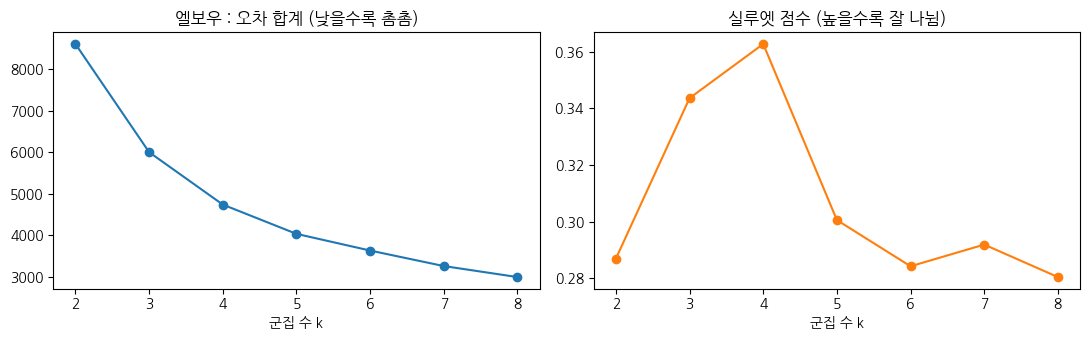

실루엣 점수가 가장 높은 k : 4


,inertia,silhouette
k,,
2,"8,599.97",0.29
3,"5,998.73",0.34
4,"4,738.21",0.36
5,"4,034.32",0.30
6,"3,633.17",0.28
7,"3,260.18",0.29
8,"2,995.48",0.28


In [9]:
# 셀 9. k = 2 ~ 8 비교 (약 30초)

results = []
for k in range(2, 9):
    # n_init=10 : 시작 위치를 10번 바꿔 돌리고 가장 좋은 결과를 씀 / random_state : 결과 고정
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    results.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X_scaled, km.labels_)})
results = pd.DataFrame(results).set_index("k")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(results.index, results["inertia"], marker="o"); axes[0].set_title("엘보우 : 오차 합계 (낮을수록 촘촘)")
axes[1].plot(results.index, results["silhouette"], marker="o", color="tab:orange"); axes[1].set_title("실루엣 점수 (높을수록 잘 나뉨)")
for ax in axes: ax.set_xlabel("군집 수 k")
plt.tight_layout(); plt.show()

best_k = int(results["silhouette"].idxmax())
print(f"실루엣 점수가 가장 높은 k : {best_k}")
results.round(3)

---
## 4. K-Means로 판매자 유형 나누기

In [10]:
# 셀 10. K-Means 학습

K = 4                                                    # 셀 9에서 실루엣 점수가 가장 높았던 k
kmeans = KMeans(n_clusters=K, n_init=20, random_state=42)
prof["segment_id"] = kmeans.fit_predict(X_scaled)        # 학습 + 판매자마다 군집 번호(0~3) 붙이기

# 군집별 특징 (중앙값 : 치우친 값에 덜 흔들림)
summary = prof.groupby("segment_id").agg(
    판매자수=("seller_id", "size"),
    주문건수=("frequency", "median"),
    판매액=("monetary", "median"),
    마지막판매후일수=("recency_days", "median"),
    활동기간일수=("tenure_days", "median"),
    평균평점=("avg_review_score", "mean"),
)
summary

,판매자수,주문건수,판매액,마지막판매후일수,활동기간일수,평균평점
segment_id,,,,,,
0,876,38.00,"4,949.71",15.00,387.50,4.07
1,218,1.00,179.90,205.50,264.50,1.59
2,461,3.00,309.00,324.00,430.00,4.31
3,947,3.00,405.30,27.00,98.00,4.29


### 유형 이름 붙이기
군집 번호(0, 1, 2, 3)는 실행할 때마다 바뀔 수 있으므로, **특징을 보고 규칙으로 이름을 붙입니다.**

| 순서 | 규칙 | 이름 |
|---|---|---|
| 1 | 평균 평점이 가장 낮은 군집 | 저평점 위험 |
| 2 | 나머지 중 판매액이 가장 큰 군집 | 핵심 우량 |
| 3 | 나머지 둘 중 마지막 판매 후 일수가 긴 군집 | 휴면 |
| 4 | 마지막 남은 군집 | 신규 성장 |

In [11]:
# 셀 11. 군집에 이름 붙이기

names = {}                 # {군집 번호: 이름}
rest = summary.copy()      # 아직 이름이 없는 군집들
names[rest["평균평점"].idxmin()] = "저평점 위험";      rest = rest.drop(index=list(names))
names[rest["판매액"].idxmax()] = "핵심 우량";          rest = rest.drop(index=rest["판매액"].idxmax())
names[rest["마지막판매후일수"].idxmax()] = "휴면";      rest = rest.drop(index=rest["마지막판매후일수"].idxmax())
names[rest.index[0]] = "신규 성장"

prof["segment"] = prof["segment_id"].map(names)
summary.index = summary.index.map(names)
order = ["핵심 우량", "신규 성장", "휴면", "저평점 위험"]
summary.loc[order]

,판매자수,주문건수,판매액,마지막판매후일수,활동기간일수,평균평점
segment_id,,,,,,
핵심 우량,876,38.00,"4,949.71",15.00,387.50,4.07
신규 성장,947,3.00,405.30,27.00,98.00,4.29
휴면,461,3.00,309.00,324.00,430.00,4.31
저평점 위험,218,1.00,179.90,205.50,264.50,1.59


**유형 해석**

| 유형 | 특징 | 관리 방향 |
|---|---|---|
| 핵심 우량 | 주문·판매액이 가장 크고 최근에도 활발 | 이탈 방지, 우수 판매자 혜택 |
| 신규 성장 | 시작한 지 얼마 안 됐고 최근 판매 있음 | 온보딩 지원, 첫 판매 경험 관리 |
| 휴면 | 오랫동안 판매가 없음 | 재활성화 캠페인 또는 정리 |
| 저평점 위험 | 평점이 매우 낮음 | 품질·배송 점검, 경고 |

> 숫자는 위 표에서 직접 확인하세요. 이름은 **사람이 해석해서 붙인 것**이고, K-Means는 "비슷한 것끼리 묶어 줄" 뿐입니다.

In [12]:
# 셀 12. 유형별 운영 지표 : 지연은 어디서 생길까? (PART 5 인사이트 10과 연결)

ops = prof.groupby("segment").agg(
    판매자수=("seller_id", "size"),
    평균배송일수=("avg_delivery_days", "mean"),
    도착지연율=("late_rate", "mean"),
    출고지연율=("ship_late_rate", "mean"),
    저평점비율=("low_review_rate", "mean"),
).loc[order]
ops.style.format({"평균배송일수": "{:.1f}", "도착지연율": "{:.1%}", "출고지연율": "{:.1%}", "저평점비율": "{:.1%}"})

,판매자수,평균배송일수,도착지연율,출고지연율,저평점비율
segment,,,,,
핵심 우량,876,13.4,8.2%,10.3%,15.0%
신규 성장,947,11.9,7.7%,8.2%,9.9%
휴면,461,13.0,5.5%,16.0%,8.8%
저평점 위험,218,21.7,30.6%,32.9%,82.8%


**해석 포인트**
- **도착 지연율**은 고객이 예정일보다 늦게 받은 비율, **출고 지연율**은 판매자가 출고 마감보다 늦게 택배사에 넘긴 비율입니다.
- **저평점 위험** 유형은 평균 배송일이 약 22일로 다른 유형(12~13일)보다 훨씬 길고, 도착 지연율(약 31%)과 출고 지연율(약 33%)도 다른 유형보다 몇 배 높습니다. 1~2점 리뷰 비율은 80%가 넘습니다.
- 단, 이 유형은 판매자 대부분이 주문 1~2건뿐이라 비율이 크게 흔들릴 수 있습니다. "한두 번의 나쁜 경험으로 평점이 무너진 판매자"로 읽는 것이 정확합니다.
- 즉, 낮은 평점이 몰린 판매자는 **판매자 출고 단계부터 늦는** 경우가 많습니다. → PART 5 인사이트 9(지연 → 나쁜 리뷰)를 판매자 단위에서 다시 확인한 셈입니다.
- 다른 유형도 출고 지연율이 도착 지연율보다 높습니다. 출고가 조금 늦어도 안내한 도착 예정일이 넉넉해서 고객에게는 제때 도착하는 경우가 많기 때문입니다.

> 💡 비즈니스 활용: 저평점 위험 판매자에게는 '출고 마감 준수' 관리가 가장 먼저입니다.

2개 축이 담은 정보량 : 75.0%


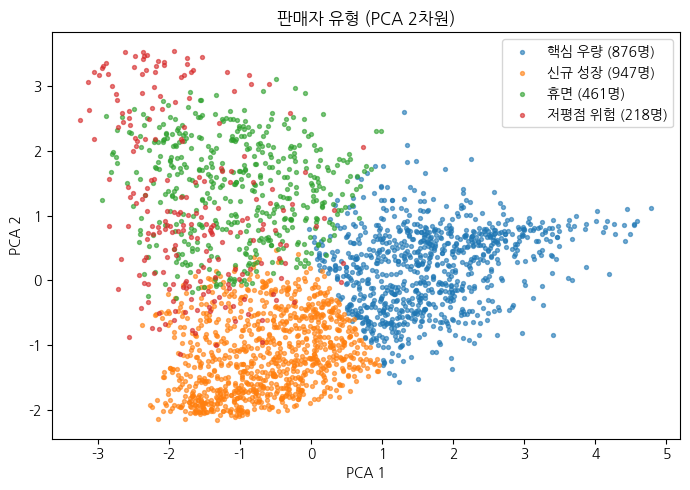

In [13]:
# 셀 13. PCA로 2차원에 그려 보기

pca = PCA(n_components=2, random_state=42)    # 특징 5개 → 2개 축으로 압축
xy = pca.fit_transform(X_scaled)              # 판매자마다 (x, y) 좌표
print(f"2개 축이 담은 정보량 : {pca.explained_variance_ratio_.sum():.1%}")

plt.figure(figsize=(7, 5))
for name in order:
    m = prof["segment"] == name
    plt.scatter(xy[m, 0], xy[m, 1], s=8, alpha=0.6, label=f"{name} ({m.sum():,}명)")
plt.xlabel("PCA 1"); plt.ylabel("PCA 2"); plt.title("판매자 유형 (PCA 2차원)")
plt.legend(); plt.tight_layout(); plt.show()

**해석**: 군집이 그림에서 어느 정도 나뉘어 보이면 잘 묶인 것입니다. 단, 5개 특징을 2개 축으로 압축했기 때문에 겹쳐 보이는 부분도 있습니다.

---
## 💾 배포용 저장

새 판매자의 유형을 판단하려면 **똑같은 순서**로 처리해야 합니다.

```
판매자 프로필 → make_segment_input() (로그 변환 + 결측 채우기) → scaler.transform() → kmeans.predict() → 유형 이름
```

| 저장 항목 | 역할 |
|---|---|
| `scaler` | 학습 때와 같은 기준으로 단위 맞추기 |
| `kmeans` | 가장 가까운 군집 중심 찾기 |
| `names` | 군집 번호 → 유형 이름 |
| `review_fill` | 리뷰 없는 판매자에게 채울 값 (학습 때 중앙값) |
| `features`, `cutoff` | 어떤 특징을, 언제 기준으로 만들었는지 |

In [14]:
# 셀 14. 배포용 저장

artifact = {
    "scaler": scaler,
    "kmeans": kmeans,
    "names": names,
    "review_fill": review_fill,
    "features": seg_features,
    "cutoff": CUTOFF,
}
save_file = f"{model_path}/part8_seller_segment.pkl"
joblib.dump(artifact, save_file, compress=3)
print("저장 완료 :", save_file)
print(f"파일 크기 : {os.path.getsize(save_file) / 1024:.0f} KB")

저장 완료 : /content/drive/MyDrive/Colab Notebooks/Data_Analysis/Olist/model/part8_seller_segment.pkl
파일 크기 : 3 KB


In [15]:
# 셀 15. 저장한 파일로 유형 판단해 보기 (STEP2 서빙에서 이렇게 사용합니다)

art = joblib.load(save_file)

def predict_segment(prof, art=art):
    X_new = make_segment_input(prof, art["review_fill"])[art["features"]]   # ① 로그 변환 + 결측 채우기
    seg_id = art["kmeans"].predict(art["scaler"].transform(X_new))         # ② 스케일링 → ③ 가장 가까운 군집
    return pd.Series(seg_id, index=prof.index).map(art["names"])           # ④ 번호 → 유형 이름

check = predict_segment(prof)
print("학습 결과와 같은가?", (check == prof["segment"]).all())
check.value_counts()

학습 결과와 같은가? True


,count
신규 성장,947
핵심 우량,876
휴면,461
저평점 위험,218


> ⚠️ **배포할 때 주의**: `recency_days`(마지막 판매 후 일수)는 **언제 계산하느냐**에 따라 값이 바뀝니다.
> 학습은 2018-05-31 기준이었지만, 실제 서비스에서는 '오늘' 기준으로 계산하게 됩니다. 시간이 많이 지나면 유형 기준을 다시 학습해야 합니다.

---
## 마무리 정리

| 확인할 내용 | 설명 |
|---|---|
| 이 파트의 핵심 | 정답 없이 비슷한 판매자끼리 묶고, 사람이 해석해서 이름을 붙였습니다. |
| 데이터 | 원본에서 기준일(2018-05-31)까지의 유효 주문으로 판매자 프로필을 만들었습니다. |
| 로그 변환 | 치우친 값을 펴지 않으면 대형 판매자 몇 명이 군집 하나를 차지합니다. |
| k 정하기 | 엘보우로 후보를 좁히고 실루엣 점수로 결정했습니다. |
| 해석 | 유형별 지연율·평점으로 관리 방향을 정할 수 있습니다. |
| 모델 저장 | 스케일러 + K-Means + 유형 이름 + 결측 채움 값을 한 파일로 저장했습니다. |
| 다음 단계 | PART 9에서 최근 활동한 판매자 중 **앞으로 판매를 멈출 판매자**를 예측합니다. |